Tarea 1 - Inteligencia Artificial

Analisis de regresion lineal: Forest Fires Dataset

Este dataset contiene datos reales del parque natural Montesinho en Portugal, recopilados entre enero del 2000 y diciembre del 2003.

Contiene 517 registros de incendios forestales.

Se muestran, la temperatura(temp), velocidad del viento (wind), humedad relativa (RH), lluvia (rain), y los indices meteorologicos FFMC, DMC, DC e ISI como caracteristicas predictoras continuas, y una variable objetivo continua "area" que representa el area quemada por el incendio en hectareas.

En este notebook se realiza: 1. Analisis exploratorio y limpieza de datos, 3. Comparacion entre nuestra clase "MyLinearRegression" (Ecuacion normal) y "LinearRegression" de sklearn, y 4. Las preguntas de analisis comnceptual.

-----------------------------------------------------------------------------

Punto 1: Analisis exploratorio de datos (EDA) y limpieza

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("forestfires.csv")
print(f"Dimensiones del dataset: {df.shape}")
df.head()

Dimensiones del dataset: (517, 13)


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB


,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


Limpieza de datos

Se verifican valores faltantes y duplicados

In [3]:
print("Valores faltantes por columna:")
print(df.isnull().sum())

duplicados = df.duplicated().sum()
print(f"\nFilas duplicadas: {duplicados}")
df = df.drop_duplicates()
print(f"Dimensiones tras eliminar duplicados: {df.shape}")

Valores faltantes por columna:
X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

Filas duplicadas: 4
Dimensiones tras eliminar duplicados: (513, 13)


Distribucion de las variables continuas

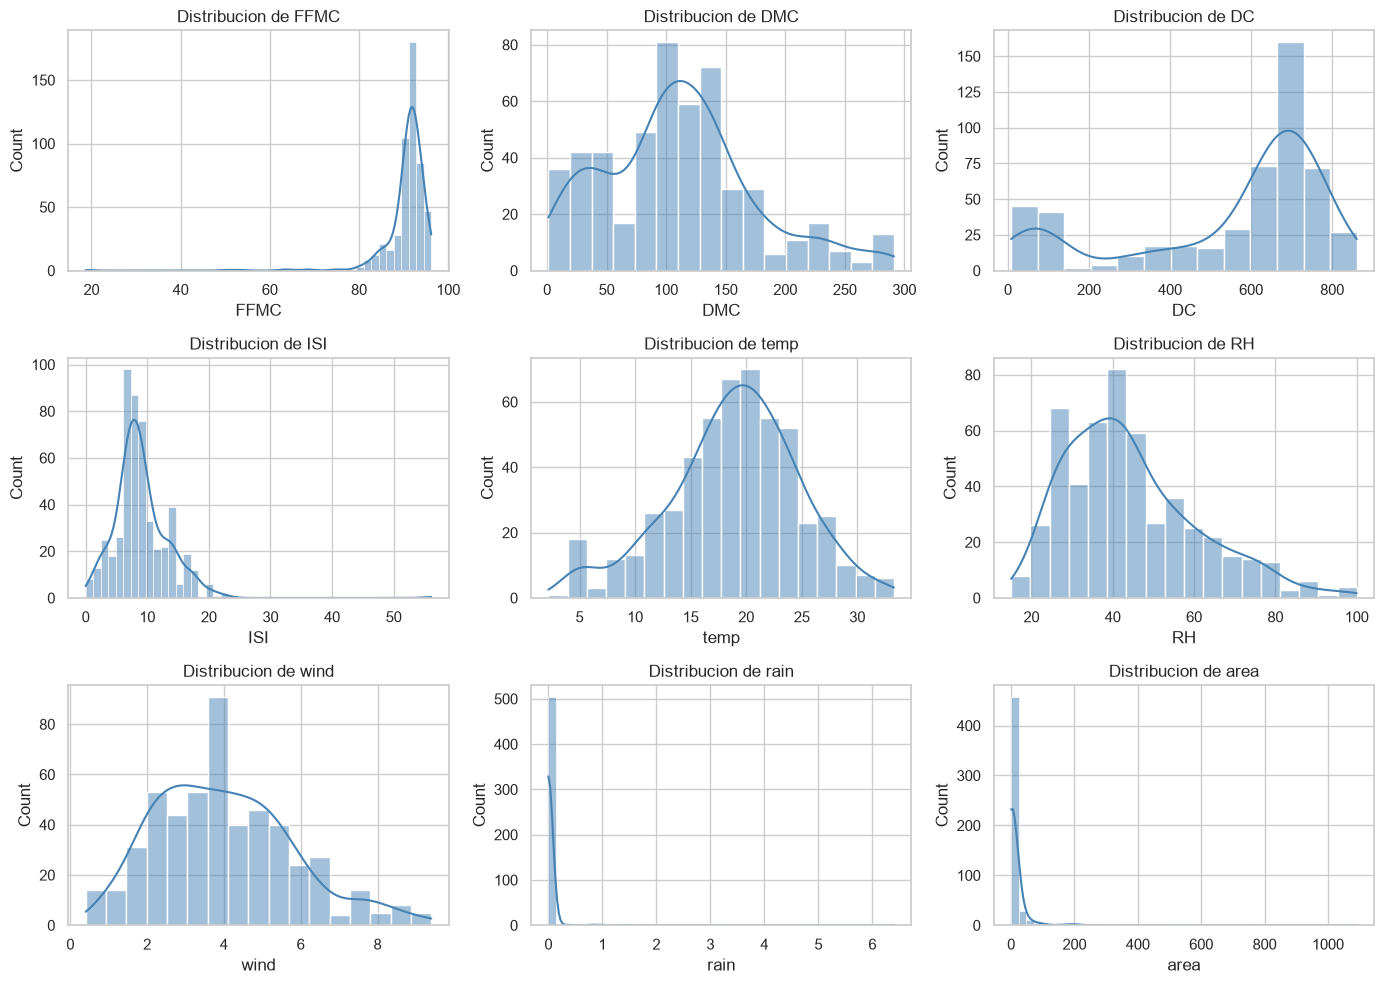

In [4]:
cols_continuas = ["FFMC", "DMC", "DC", "ISI", "temp", "RH", "wind", "rain", "area"]

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), cols_continuas):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribucion de {col}")
plt.tight_layout()
plt.show()

La variable objetivo area esta muy sesgada a la derecha lo que nos dice que la mayoria de incendios queman areas pequenas y unos pocos areas enormes.

Es util visualizarla en escala logaritmica.

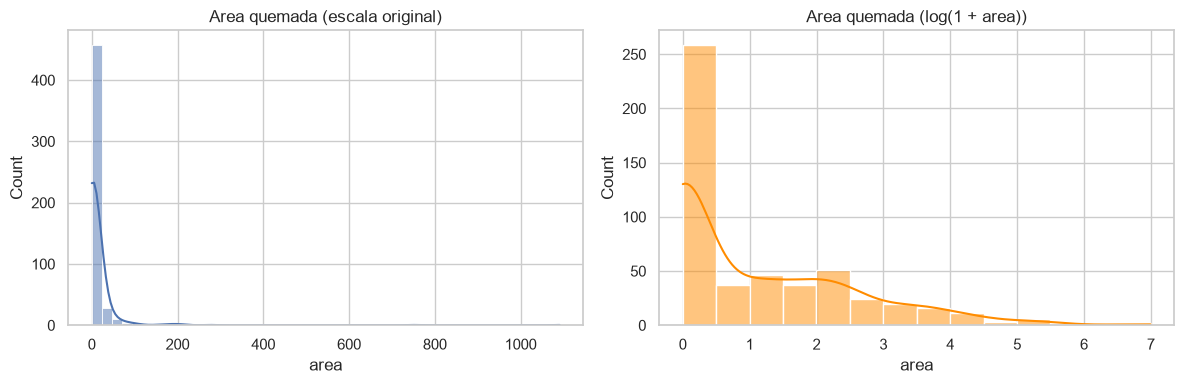

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["area"], kde=True, ax=axes[0])
axes[0].set_title("Area quemada (escala original)")
sns.histplot(np.log1p(df["area"]), kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Area quemada (log(1 + area))")
plt.tight_layout()
plt.show()

Relacion entre la predictoras y la varaible objetivo

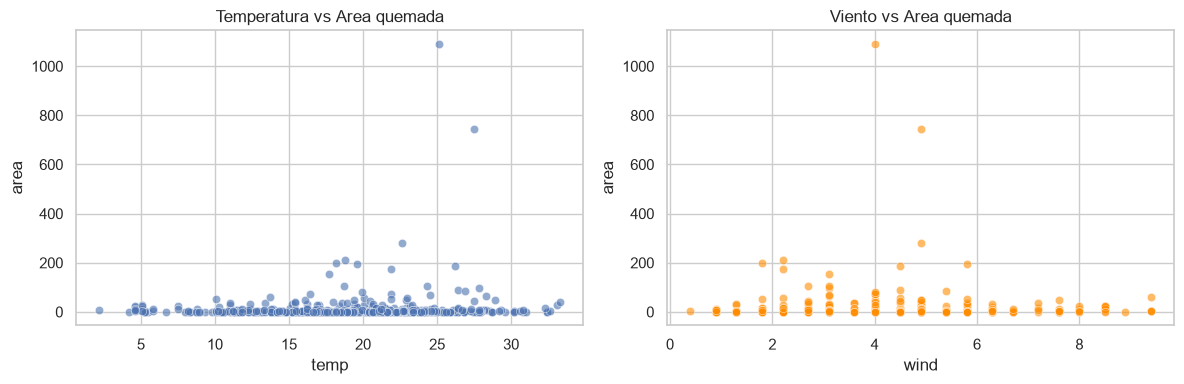

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="temp", y="area", ax=axes[0], alpha=0.6)
axes[0].set_title("Temperatura vs Area quemada")
sns.scatterplot(data=df, x="wind", y="area", ax=axes[1], alpha=0.6, color="darkorange")
axes[1].set_title("Viento vs Area quemada")
plt.tight_layout()
plt.show()

Matriz de correlacion de las variables numericas

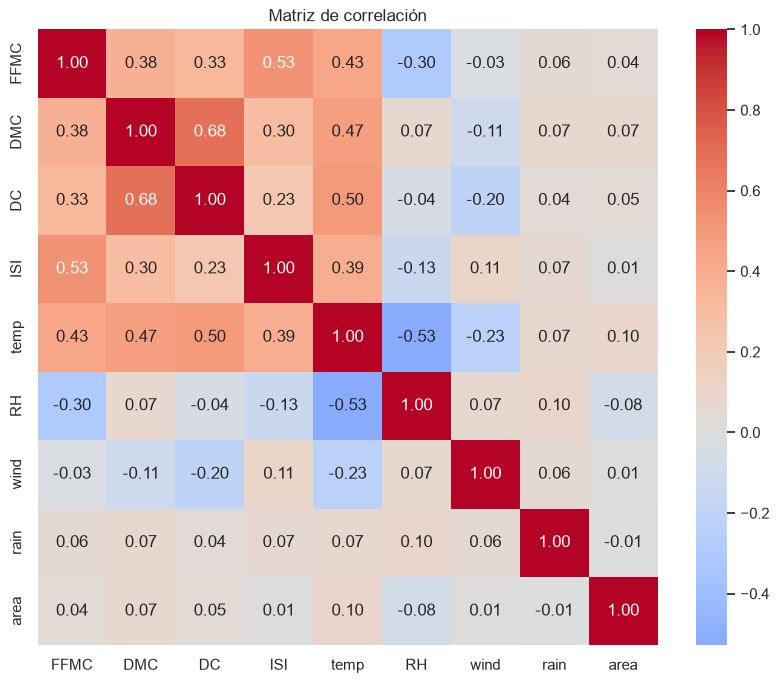

In [7]:
plt.figure(figsize=(10, 8))
corr = df[cols_continuas].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.show()

Con esto podemos obsesrvar que:

El dataset no tiene valores faltantes y los duplicantes fueron eliminados.
temp/wind/RH/rain/FFMC/DMC/DC/ISI son continuas y month y day son categoricas.

La variable objetivo "area" tiene un fuerte sesgo positivo.

Las correlaciones lineales individuales con area son debiles, lo que anticipa que un modelo lienal simple tendra un ajuste limitado

-----------------------------------------------------------------------------

Punto 3: Entrenamiento y comparacion con sklearn

Para este punto primero definimos las caracteristicas predictoras (temp y wind) y la variable objetivo (area) y dividimos los datos ej conjunto de entrenamiento (80%) y prueba (20%)

In [8]:
from sklearn.model_selection import train_test_split

X = df[["temp", "wind"]].values

y = df["area"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} ejemplos | Prueba: {X_test.shape[0]} ejemplos")

Entrenamiento: 410 ejemplos | Prueba: 103 ejemplos


Modelo con nuestra clase MyLinearRegression (Ecuacion normal)

In [15]:
from my_linear_regression import MyLinearRegression

my_model = MyLinearRegression()
my_model.fit(X_train, y_train)

y_pred_train_mine = my_model.predict(X_train)
y_pred_test_mine = my_model.predict(X_test)

print("=== MyLinearRegression (Ecuación Normal) ===")
print(f"Coeficientes b_      : {my_model.b_}")
print(f"Intercepto intercept_: {my_model.intercept_:.4f}")
print(f"MSE entrenamiento    : {my_model.mse(y_train, y_pred_train_mine):.4f}")
print(f"MSE prueba           : {my_model.mse(y_test, y_pred_test_mine):.4f}")
print(f"R² entrenamiento     : {my_model.r2_score(y_train, y_pred_train_mine):.4f}")
print(f"R² prueba            : {my_model.r2_score(y_test, y_pred_test_mine):.4f}")

=== MyLinearRegression (Ecuación Normal) ===
Coeficientes b_      : [1.3779026  1.42090165]
Intercepto intercept_: -17.5100
MSE entrenamiento    : 4928.0652
MSE prueba           : 469.4975
R² entrenamiento     : 0.0126
R² prueba            : -0.2192


Modelo con LinearRegression de sklearn

In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

y_pred_train_sk = sk_model.predict(X_train)
y_pred_test_sk = sk_model.predict(X_test)

print("=== LinearRegression (sklearn) ===")
print(f"Coeficientes coef_      : {sk_model.coef_}")
print(f"Intercepto intercept_   : {sk_model.intercept_:.4f}")
print(f"MSE entrenamiento       : {mean_squared_error(y_train, y_pred_train_sk):.4f}")
print(f"MSE prueba              : {mean_squared_error(y_test, y_pred_test_sk):.4f}")
print(f"R² entrenamiento        : {r2_score(y_train, y_pred_train_sk):.4f}")
print(f"R² prueba               : {r2_score(y_test, y_pred_test_sk):.4f}")

=== LinearRegression (sklearn) ===
Coeficientes coef_      : [1.3779026  1.42090165]
Intercepto intercept_   : -17.5100
MSE entrenamiento       : 4928.0652
MSE prueba              : 469.4975
R² entrenamiento        : 0.0126
R² prueba               : -0.2192


Comparacion de resultados

In [11]:
comparacion = pd.DataFrame({
    "MyLinearRegression": [
        my_model.b_[0], my_model.b_[1], my_model.intercept_,
        my_model.mse(y_train, y_pred_train_mine),
        my_model.mse(y_test, y_pred_test_mine),
        my_model.r2_score(y_train, y_pred_train_mine),
        my_model.r2_score(y_test, y_pred_test_mine),
    ],
    "sklearn": [
        sk_model.coef_[0], sk_model.coef_[1], sk_model.intercept_,
        mean_squared_error(y_train, y_pred_train_sk),
        mean_squared_error(y_test, y_pred_test_sk),
        r2_score(y_train, y_pred_train_sk),
        r2_score(y_test, y_pred_test_sk),
    ],
}, index=["coef_ (temp)", "coef_ (wind)", "intercept_",
          "MSE train", "MSE test", "R² train", "R² test"])

comparacion["Diferencia absoluta"] = (
    comparacion["MyLinearRegression"] - comparacion["sklearn"]
).abs()
comparacion

,MyLinearRegression,sklearn,Diferencia absoluta
coef_ (temp),1.377903,1.377903,2.664535e-15
coef_ (wind),1.420902,1.420902,6.661338e-16
intercept_,-17.509991,-17.509991,2.131628e-14
MSE train,4928.065197,4928.065197,9.094947e-13
MSE test,469.497459,469.497459,5.684342e-13
R² train,0.012626,0.012626,1.110223e-16
R² test,-0.219158,-0.219158,1.332268e-15


Verificacion numerica: Predicciones practicamente identicas

In [13]:
print("Maxima diferencia en predicciones (test):",
      np.max(np.abs(y_pred_test_mine - y_pred_test_sk)))

Maxima diferencia en predicciones (test): 6.394884621840902e-14


Conclusion: Ambos modelos producen coeficientes, intercepto, MSE y R² practicamente identicos (las diferencias son del orden del error de redondeo de punto flotante). Esto es lo esperado: ambos resuelven el mismo problema de minimos cuadrados, nuestra clase mediante la Ecuacion Normal θ = (XᵀX)⁻¹Xᵀy y sklearn mediante descomposicion SVD, por lo que convergen a la misma solucion optima.

Visualizacion de predicciones vs valores reales

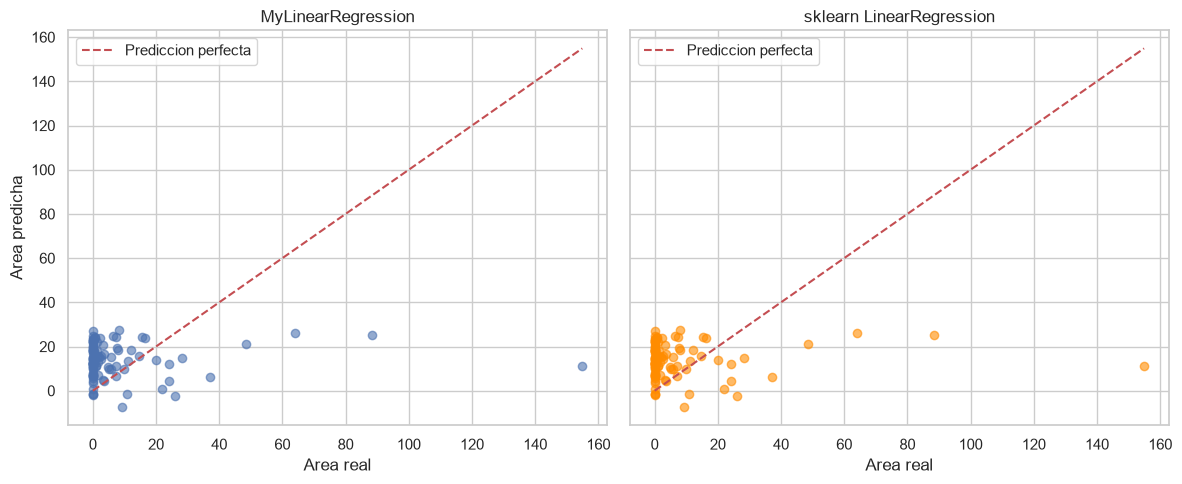

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].scatter(y_test, y_pred_test_mine, alpha=0.6)
axes[0].plot([0, y_test.max()], [0, y_test.max()], "r--", label="Prediccion perfecta")
axes[0].set_xlabel("Area real"); axes[0].set_ylabel("Area predicha")
axes[0].set_title("MyLinearRegression"); axes[0].legend()
axes[1].scatter(y_test, y_pred_test_sk, alpha=0.6, color="darkorange")
axes[1].plot([0, y_test.max()], [0, y_test.max()], "r--", label="Prediccion perfecta")
axes[1].set_xlabel("Area real")
axes[1].set_title("sklearn LinearRegression"); axes[1].legend()
plt.tight_layout()
plt.show()

-----------------------------------------------------------------------------

Punto 4: preguntas de analisis conceptual y discusion

4.1 Particion de datos y validacion

Por que es fundamental evaluar el modelo sobre un conjunto de prueba no utilizado durante el ajuste?

El objetivo de un modelo de aprendizaje supervisado no es memorizar los datos que ya vio, sino generalizar: hacer buenas predicciones sobre observaciones nuevas. Si evaluamos unicamente sobre los datos de entrenamiento, las metricas (MSE, R2) miden que tan bien el modelo reproduce esos datos especificos, no que tan bien predice datos futuros. El error de entrenamiento es un estimador optimista del error real, porque el modelo ya se ajusto precisamente para minimizar ese error.

Que riesgo se corre al reportar solo metricas de entrenamiento?

El riesgo principal es reportar un desempeno enganosamente bueno que no se sostendra en produccion. Un modelo suficientemente flexible puede reducir el error de entrenamiento casi a cero (memorizando incluso el ruido), mientras su error sobre datos nuevos es pesimo. Sin un conjunto de prueba, no hay forma de detectar esta situacion.

Relacion con el dilema sesgo-varianza:

Un modelo demasiado simple (alto sesgo, underfitting) tiene error alto tanto en entrenamiento como en prueba: no captura la estructura real de los datos.

Un modelo demasiado complejo (alta varianza, overfitting) tiene error de entrenamiento muy bajo pero error de prueba alto: se ajusta al ruido del conjunto de entrenamiento y no generaliza.

El punto optimo esta en un nivel intermedio de flexibilidad, y solo es posible encontrarlo comparando el error de entrenamiento con el de prueba. Por eso la particion de datos (o validacion cruzada) es la herramienta estandar para diagnosticar donde estamos en ese dilema.

4.2 Diagnostico de sesgo y varianza

Analisis del desempeno obtenido (R2 y MSE en entrenamiento y prueba):

Observando las metricas del punto 3, el modelo presenta:

Un R2 muy cercano a 0 (incluso negativo en el conjunto de prueba), tanto en entrenamiento como en prueba. Un R2 aproximadamente 0 significa que el modelo apenas explica mas varianza que simplemente predecir la media del area quemada; un R2 negativo indica que en datos nuevos rinde incluso peor que la media.

Errores de entrenamiento y de prueba del mismo orden de magnitud, sin una brecha grande entre ambos.

Diagnostico: alto sesgo (underfitting), no alta varianza.

La justificacion es doble:

Si hubiera overfitting, veriamos un error de entrenamiento notablemente menor que el de prueba. Aqui ambos errores son similares (y ambos altos), la firma clasica del underfitting.

La complejidad del modelo no es acorde con la naturaleza del dataset. Una regresion lineal con solo dos predictoras (temp y wind) supone que el area quemada es una combinacion lineal de esas variables, pero el fenomeno real es altamente no lineal: el EDA mostro correlaciones individuales muy debiles con area, y la variable objetivo tiene una distribucion extremadamente sesgada (muchos ceros y valores atipicos enormes). Dos variables lineales no pueden capturar esa estructura.

Posibles mejoras (manteniendo el espiritu del modelo): incorporar mas predictoras (FFMC, DMC, DC, ISI, RH), aplicar una transformacion logaritmica al objetivo (log(1 + area)) para reducir el sesgo de la distribucion, o usar terminos de interaccion/polinomiales. Estas modificaciones aumentarian la flexibilidad del modelo aumentando la varianza, pero reduciendo el sesgo y solo evaluando sobre el conjunto de prueba podriamos verificar si la mejora realmente generaliza.